# GUIDED → INDI handover: X-frame motor-ordering fix (anixpkgs #646)

[anixpkgs #646](https://github.com/goromal/anixpkgs/pull/646) together with
[indi-harness #5](https://github.com/goromal/indi-harness/pull/5) fixes the measured-RPM
trajectory SITL VM. The JSON rotor-dynamics simulator (`QuadParams`) models an
**X** quad, but the VM left ArduPilot at its default `FRAME_TYPE=0` (**Plus**). The mixer
therefore drove the wrong motors for roll and pitch, and the stock GUIDED hold was unstable
before the custom controller ever engaged. The PR sets `FRAME_TYPE=1` and makes the scorer
reject any log whose frame layout does not match the plant.

This notebook reads the SITL DataFlash logs (`flight.BIN`; ArduPilot logs, not ROS bags)
and checks the PR's claims directly:

| # | Claim | Gate |
|---|---|---|
| 1 | Logged layout is X (`FRAME_CLASS=1`, `FRAME_TYPE=1`) | exact |
| 2 | Stock GUIDED hold settles before INDI engages | peak roll/pitch rate < 1 rad/s over the 2 s before handover |
| 3 | Trajectory tracking matches or beats the benign-SITL baseline | per-case RMS ≤ 1.5 × baseline |
| 4 | No actuator saturation; measured-RPM path live | sat ≤ 2 %, INDC fallback < 50 % |
| 5 | *(still open)* ω̇ inversion fidelity | roll/pitch NRMSE ≤ 0.6 — **the PR does not claim to close this** |

Two runs flew the same firmware and the same two-case battery (`circle_slow`, `lemniscate_fast`):

* **before**: `handover-trajectory-run/`, Plus layout (pre-fix). The runner aborted at the handover gate.
* **after**: `handover-trajectory-frame-x/`, X layout (PR #646).

The existing logging already covers every claim, so no extra SITL logging was needed:
`INDB` (reference vs. measured position, outer-loop fallback), `INDI` (predicted vs. measured
ω̇, increment, saturation), `INDC` (measured rotor speed, RPM fallback), `IMU` (body rates),
and `SIM` (simulator-truth attitude and position).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from pymavlink import DFReader

from geometry import SO3, SE3
from mesh_plotter.meshes import Line, MeshBase, Axes3DMesh
from mesh_plotter.animator_3d import Animator3D

DATA_ROOT = Path("/data/andrew/dev/drone/data")
RUNS = {
    "before (Plus)": DATA_ROOT / "handover-trajectory-run",
    "after (X)": DATA_ROOT / "handover-trajectory-frame-x",
}
COLORS = {"before (Plus)": "tab:red", "after (X)": "tab:blue"}
RATE_LIMIT_RAD_S = 1.0
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Load the logs

A single pass over each log collects the message types below into arrays keyed by field,
with `TimeUS` converted to seconds since boot (`t`). Only IMU instance 0 is kept.

In [2]:
MESSAGE_TYPES = ["IMU", "SIM", "INDB", "INDI", "INDC", "ATT"]


def load_dataflash(path):
    log = DFReader.DFReader_binary(str(path))
    rows = {k: [] for k in MESSAGE_TYPES}
    parameters, text, modes = {}, [], []
    while (m := log.recv_match(type=MESSAGE_TYPES + ["PARM", "MSG", "MODE"])) is not None:
        kind = m.get_type()
        if kind == "PARM":
            parameters[m.Name] = m.Value
        elif kind == "MSG":
            text.append((m.TimeUS / 1e6, m.Message))
        elif kind == "MODE":
            modes.append((m.TimeUS / 1e6, m.Mode))
        elif kind == "IMU" and m.I != 0:
            continue
        else:
            rows[kind].append(m.to_dict())
    series = {}
    for kind, messages in rows.items():
        if not messages:
            series[kind] = {}
            continue
        fields = [f for f in messages[0] if f != "mavpackettype"]
        series[kind] = {f: np.array([msg[f] for msg in messages]) for f in fields}
        series[kind]["t"] = series[kind]["TimeUS"] / 1e6
    return {"series": series, "parameters": parameters, "text": text, "modes": modes}


logs = {name: load_dataflash(run / "flight.BIN") for name, run in RUNS.items()}
handover = {name: json.loads((run / "handover.json").read_text()) for name, run in RUNS.items()}
after_dir = RUNS["after (X)"]
score = json.loads((after_dir / "indi_score.json").read_text())
flown_cases = json.loads((after_dir / "indi_flatness_flown.json").read_text())
for name, log in logs.items():
    counts = {k: len(v.get("t", [])) for k, v in log["series"].items()}
    print(f"{name:14s} {counts}")

before (Plus)  {'IMU': 7624, 'SIM': 3049, 'INDB': 0, 'INDI': 0, 'INDC': 0, 'ATT': 3049}
after (X)      {'IMU': 2428, 'SIM': 971, 'INDB': 21406, 'INDI': 21407, 'INDC': 21406, 'ATT': 971}


## 1. Logged actuator layout

In [3]:
LAYOUT_KEYS = ["FRAME_CLASS", "FRAME_TYPE", "CC3_USE_RPM", "CC3_G1_RP", "CC3_G1_YAW",
               "MOT_THST_EXPO", "MOT_SPIN_MIN", "MOT_SPIN_MAX"]
print(f"{'parameter':14s}" + "".join(f"{n:>16s}" for n in logs))
for key in LAYOUT_KEYS:
    print(f"{key:14s}" + "".join(f"{logs[n]['parameters'].get(key, float('nan')):16g}" for n in logs))
for name, log in logs.items():
    frame_text = [m for _, m in log["text"] if m.startswith("Frame:")]
    print(f"{name:14s} firmware banner: {frame_text}")

parameter        before (Plus)       after (X)
FRAME_CLASS                  1               1
FRAME_TYPE                   0               1
CC3_USE_RPM                  1               1
CC3_G1_RP                  500             500
CC3_G1_YAW                28.8            28.8
MOT_THST_EXPO                0               0
MOT_SPIN_MIN                 0               0
MOT_SPIN_MAX                 1               1
before (Plus)  firmware banner: ['Frame: QUAD/PLUS']
after (X)      firmware banner: ['Frame: QUAD/X']


The only difference between the two runs is `FRAME_TYPE`. The firmware banner confirms that
the pre-fix vehicle mixed for a `QUAD/PLUS` airframe while the simulator flew an X.

## 2. Stock GUIDED hold before handover

Roll/pitch body-rate magnitude $\sqrt{p^2+q^2}$ from the IMU, aligned on the arming
that precedes takeoff. The shaded band marks the 2 s settlement window that the runner checks
before it enables the custom controller. The dashed line marks the 1 rad/s gate.

before (Plus)  stock-hold rate peak (first 4 s at 9.5 m): 4.1911 rad/s; runner verdict: RuntimeError: unsettled stock handover: peak roll/pitch rate 4.384 rad/s >= 1.000
after (X)      stock-hold rate peak (first 4 s at 9.5 m): 0.0054 rad/s; runner verdict: settled


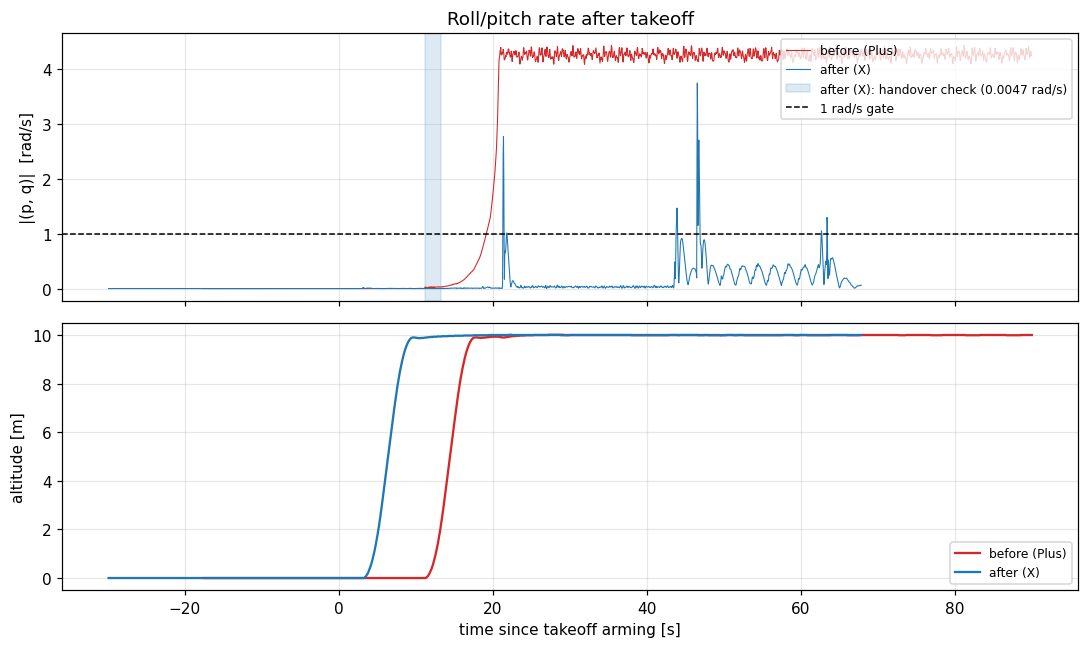

In [4]:
def takeoff_arm_time(log):
    arms = [t for t, m in log["text"] if m == "Arming motors"]
    return arms[-1]


def hover_start_time(log, altitude_m=9.5):
    # First simulator-truth sample at hold altitude: the stock GUIDED hold the runner checks.
    sim = log["series"]["SIM"]
    return sim["t"][np.argmax(sim["Alt"] - sim["Alt"][0] > altitude_m)]


fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name, log in logs.items():
    imu, sim = log["series"]["IMU"], log["series"]["SIM"]
    t0 = takeoff_arm_time(log)
    rate = np.hypot(imu["GyrX"], imu["GyrY"])
    window = imu["t"] - t0 < 90
    axes[0].plot(imu["t"][window] - t0, rate[window], color=COLORS[name], lw=0.7, label=name)
    sim_window = sim["t"] - t0 < 90
    axes[1].plot(sim["t"][sim_window] - t0, sim["Alt"][sim_window] - sim["Alt"][0],
                 color=COLORS[name], label=name)
    check = handover[name].get("handover")
    if check:
        end = check["end_boot_s"] - t0
        axes[0].axvspan(end - check["history_s"], end, color=COLORS[name], alpha=0.15,
                        label=f"{name}: handover check ({check['peak_roll_pitch_rate_rad_s']:.4f} rad/s)")
axes[0].axhline(RATE_LIMIT_RAD_S, color="k", ls="--", lw=1, label="1 rad/s gate")
axes[0].set_ylabel("|(p, q)|  [rad/s]")
axes[0].set_title("Roll/pitch rate after takeoff")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_ylabel("altitude [m]")
axes[1].set_xlabel("time since takeoff arming [s]")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()

for name, log in logs.items():
    imu = log["series"]["IMU"]
    t0 = hover_start_time(log)
    hover = (imu["t"] > t0) & (imu["t"] < t0 + 4)
    print(f"{name:14s} stock-hold rate peak (first 4 s at 9.5 m): "
          f"{np.max(np.hypot(imu['GyrX'][hover], imu['GyrY'][hover])):.4f} rad/s; "
          f"runner verdict: {handover[name].get('error', 'settled')}")

In the Plus run the stock controller holds altitude, but it enters a roughly 4.4 rad/s
limit cycle near the end of the climb that never decays. The runner correctly refused to hand
over. In the X run the same hold is quiet: the handover-check peak is 0.0047 rad/s, about
1000× lower. The X-run spikes about 21, 45, and 63 s after arming are INDI case-engagement and
case-end transients, covered in section 3.

### Hover attitude, simulator truth (mesh-plotter)

4 s of stock hold at altitude from each run, rendered with an X-quad line mesh from the `SIM` truth pose.
Both bodies are placed side by side in one scene (before on the left, after on the right). The
blue stick is the body thrust axis and the gray dotted stick is vertical.
`SIM` is logged at 10 Hz, so the animation shows the true tilt amplitude (about ±7.5° before
the fix) but aliases its frequency. For display, NED/FRD is converted to a z-up NWU/FLU frame.

In [5]:
NED_TO_NWU = np.diag([1.0, -1.0, -1.0])
ARM_LENGTH_M = 0.6


def quad_mesh(arm=ARM_LENGTH_M, thrust_axis=0.4):
    # X layout in FLU body axes: arms at +/-45 deg; front arms red, rear arms black;
    # a blue stick along body up (the thrust axis) makes tilt easy to read.
    lines = []
    for angle, color in [(45, "red"), (-45, "red"), (135, "black"), (-135, "black")]:
        a = np.deg2rad(angle)
        lines.append(Line([np.zeros(3), arm * np.array([np.cos(a), np.sin(a), 0.0])], color=color))
    lines.append(Line([np.zeros(3), np.array([0.0, 0.0, thrust_axis * arm])], color="blue"))
    return MeshBase(lines=lines)


def static_mesh(points, color, spec="-"):
    return MeshBase(lines=[Line([np.asarray(p, float) for p in points], color=color, spec=spec)])


def sim_pose_nwu(sim, index):
    # SIM Q1..Q4 is (w, x, y, z) for NED <- FRD. Conjugate both frames to get NWU <- FLU.
    w, x, y, z = (sim[k][index] for k in ("Q1", "Q2", "Q3", "Q4"))
    q = np.array([w, x, y, z]) / np.linalg.norm([w, x, y, z])
    w, x, y, z = q
    R_ned_frd = np.array([
        [1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
        [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
        [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)],
    ])
    return SO3.fromR(NED_TO_NWU @ R_ned_frd @ NED_TO_NWU)


def hover_sequence(log, start_s, duration_s, offset_xyz):
    sim = log["series"]["SIM"]
    t0 = hover_start_time(log) + start_s
    idx = np.flatnonzero((sim["t"] >= t0) & (sim["t"] <= t0 + duration_s))
    poses = [SE3.fromVecAndQuat(np.asarray(offset_xyz, float), sim_pose_nwu(sim, i)) for i in idx]
    return poses, list(sim["t"][idx] - t0)


# Keep the embedded animations small: low-dpi JPEG frames.
ANIMATION_STYLE = {"figure.dpi": 72, "figure.figsize": (6.0, 4.5), "animation.frame_format": "jpeg"}
plt.rcParams["animation.embed_limit"] = 40.0
# Window start after reaching altitude: both are pure stock GUIDED hold. The Plus run
# has fully developed its limit cycle 4 s in; the X run hands over to INDI about 5 s in.
HOVER_WINDOW_START_S = {"before (Plus)": 4.0, "after (X)": 0.0}
with plt.rc_context(ANIMATION_STYLE):
    animator = Animator3D(xlim=(-0.6, 0.6), ylim=(-1.6, 1.6), zlim=(-0.3, 0.9))
# Viewed from the north (+x, NWU) looking south, -y (east) appears on the left.
for name, y_offset in [("before (Plus)", -0.8), ("after (X)", 0.8)]:
    poses, times = hover_sequence(logs[name], HOVER_WINDOW_START_S[name], 4.0, [0.0, y_offset, 0.0])
    animator.addMeshSequence(quad_mesh(thrust_axis=1.3), poses, times)
    level = SE3.fromVecAndQuat(np.array([0.0, y_offset, 0.0]), SO3.identity())
    animator.addMeshSequence(static_mesh([[0, 0, 0], [0, 0, 0.8]], "gray", ":"), [level, level],
                             [times[0], times[-1]])
animator.ax.view_init(elev=10, azim=0)
hover_animation = animator.animate(dt=0.1, notebook_mode=True)
plt.close(animator.fig)
with plt.rc_context(ANIMATION_STYLE):
    display(HTML(hover_animation.to_jshtml()))

## 3. Trajectory tracking under INDI (X run)

`INDB.FB == 0` marks ticks where the DDS flatness reference drives the outer loop. Each
contiguous active block is one flown case, in the order recorded in `indi_flatness_flown.json`.

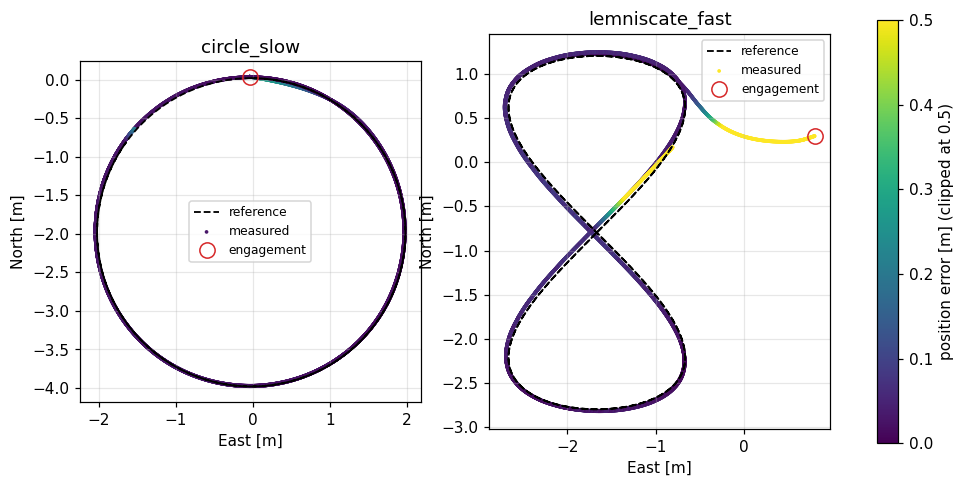

In [6]:
indb = logs["after (X)"]["series"]["INDB"]
reference = np.column_stack([indb["RPx"], indb["RPy"], indb["RPz"]])
measured = np.column_stack([indb["Px"], indb["Py"], indb["Pz"]])
active = indb["FB"] == 0
edges = np.flatnonzero(np.diff(np.r_[0, active.astype(int), 0]))
blocks = list(zip(edges[::2], edges[1::2]))
case_names = [c["case"] for c in flown_cases]
assert len(blocks) == len(case_names), (len(blocks), case_names)

cases = {}
for name, (i, j) in zip(case_names, blocks):
    error = np.linalg.norm(reference[i:j] - measured[i:j], axis=1)
    cases[name] = {"slice": slice(i, j), "t": indb["t"][i:j] - indb["t"][i], "error": error}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, case) in zip(axes, cases.items()):
    s = case["slice"]
    ax.plot(reference[s, 1], reference[s, 0], "k--", lw=1.2, label="reference")
    sc = ax.scatter(measured[s, 1], measured[s, 0], c=case["error"], s=2, cmap="viridis",
                    vmin=0, vmax=0.5, label="measured")
    ax.plot(measured[s.start, 1], measured[s.start, 0], "o", mfc="none", mec="tab:red", ms=10,
            label="engagement")
    ax.set_aspect("equal")
    ax.set_xlabel("East [m]")
    ax.set_ylabel("North [m]")
    ax.set_title(name)
    ax.legend(fontsize=8, loc="best")
fig.colorbar(sc, ax=axes, label="position error [m] (clipped at 0.5)")

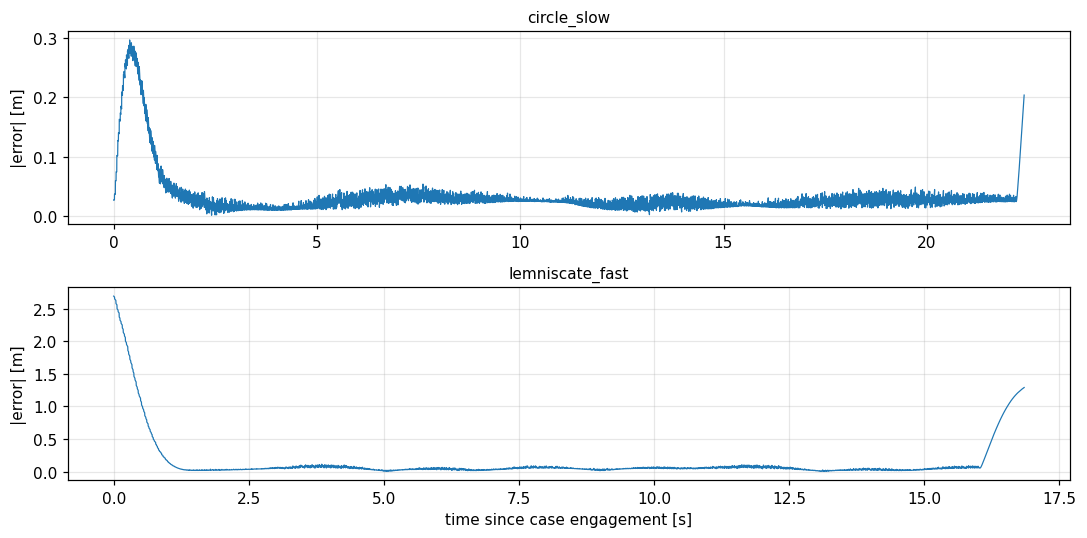

In [7]:
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 5), sharex=False)
for ax, (name, case) in zip(axes, cases.items()):
    ax.plot(case["t"], case["error"], lw=0.8)
    ax.set_ylabel("|error| [m]")
    ax.set_title(name, fontsize=10)
axes[-1].set_xlabel("time since case engagement [s]")
fig.tight_layout()

The error spike at the start of `lemniscate_fast` is a harness sequencing artifact, not a
controller fault. The case origin is latched where `circle_slow` ended, but during the roughly
2.5 s stock-hold gap between cases the GUIDED hold flew the vehicle back toward its hold
target. The lemniscate therefore engages with a reference about 2.4 m away from the vehicle.
At the end of each case the reference stops abruptly, with no deceleration segment, and the
vehicle coasts about 1 m. The table below separates these edge effects from steady tracking.

In [8]:
EDGE_S = 1.5
baseline = score["baseline"]
reported = {c["case"]: c["rms_m"] for c in score["per_case"]}
print(f"{'case':16s}{'RMS (all)':>11s}{'scorer':>9s}{'RMS (trim)':>12s}{'max (trim)':>12s}"
      f"{'peak first/last 1.5 s':>24s}{'baseline':>10s}{'gate 1.5x':>11s}  verdict")
for name, case in cases.items():
    rms_all = np.sqrt(np.mean(case["error"] ** 2))
    trim = (case["t"] > EDGE_S) & (case["t"] < case["t"][-1] - EDGE_S)
    rms_trim = np.sqrt(np.mean(case["error"][trim] ** 2))
    gate = 1.5 * baseline[name]
    print(f"{name:16s}{rms_all:11.3f}{reported[name]:9.3f}{rms_trim:12.3f}"
          f"{case['error'][trim].max():12.3f}"
          f"{case['error'][case['t'] <= EDGE_S].max():12.2f}{case['error'][case['t'] >= case['t'][-1] - EDGE_S].max():12.2f}"
          f"{baseline[name]:10.3f}{gate:11.3f}  "
          f"{'PASS' if rms_all <= gate else 'FAIL'}")
print(f"(trim drops the first and last {EDGE_S} s of each case; gate uses the untrimmed RMS)")

case              RMS (all)   scorer  RMS (trim)  max (trim)   peak first/last 1.5 s  baseline  gate 1.5x  verdict
circle_slow           0.052    0.052       0.026       0.055        0.30        0.20     0.485      0.727  PASS
lemniscate_fast       0.406    0.406       0.048       0.113        2.70        1.29     0.711      1.067  PASS
(trim drops the first and last 1.5 s of each case; gate uses the untrimmed RMS)


### Lemniscate in 3D (mesh-plotter)

The vehicle pose comes from `SIM` truth; the body is drawn at the `INDB`-measured position
relative to the case origin. A small axes triad follows the reference position, and the
reference path is drawn as a dashed line. The first second shows the 2.4 m engagement
transient described above.

In [9]:
def interpolate_rows(t_query, t, values):
    return np.column_stack([np.interp(t_query, t, values[:, k]) for k in range(values.shape[1])])


name = "lemniscate_fast"
case = cases[name]
s = case["slice"]
origin = np.array(flown_cases[case_names.index(name)]["origin"])
t_case = indb["t"][s]
sim = logs["after (X)"]["series"]["SIM"]
sim_idx = np.flatnonzero((sim["t"] >= t_case[0]) & (sim["t"] <= t_case[-1]))
times = list(sim["t"][sim_idx] - t_case[0])
meas_nwu = interpolate_rows(sim["t"][sim_idx], t_case, measured[s] - origin) @ NED_TO_NWU
ref_nwu = interpolate_rows(sim["t"][sim_idx], t_case, reference[s] - origin) @ NED_TO_NWU

body_poses = [SE3.fromVecAndQuat(p, sim_pose_nwu(sim, i)) for p, i in zip(meas_nwu, sim_idx)]
ref_poses = [SE3.fromVecAndQuat(p, SO3.identity()) for p in ref_nwu]
path = (reference[s][::20] - origin) @ NED_TO_NWU
identity = SE3.identity()

span = np.max(np.abs(path[:, :2])) + 0.8
with plt.rc_context(ANIMATION_STYLE):
    animator = Animator3D(xlim=(-span, span), ylim=(-span, span), zlim=(-1.0, 1.0))
animator.addMeshSequence(static_mesh(path, "gray", "--"), [identity, identity], [times[0], times[-1]])
animator.addMeshSequence(Axes3DMesh(scale=0.3), ref_poses, times)
animator.addMeshSequence(quad_mesh(0.35), body_poses, times)
animator.ax.view_init(elev=35, azim=-60)
lemniscate_animation = animator.animate(dt=0.2, notebook_mode=True)
plt.close(animator.fig)
with plt.rc_context(ANIMATION_STYLE):
    display(HTML(lemniscate_animation.to_jshtml()))

## 4. Actuator health during INDI flight (X run)

* `INDI.S`: saturation flag per INDI tick.
* `INDC.FB`: 1 when RPM telemetry is stale and the measured-actuator path falls back
  to the previous command.
* `INDC.O0..O3`: measured rotor speed per motor.

saturation fraction : 0.0000  (gate <= 0.02)
RPM fallback frac   : 0.0000  (gate < 0.5)
mean |rotor speed|  : 498.1 rad/s


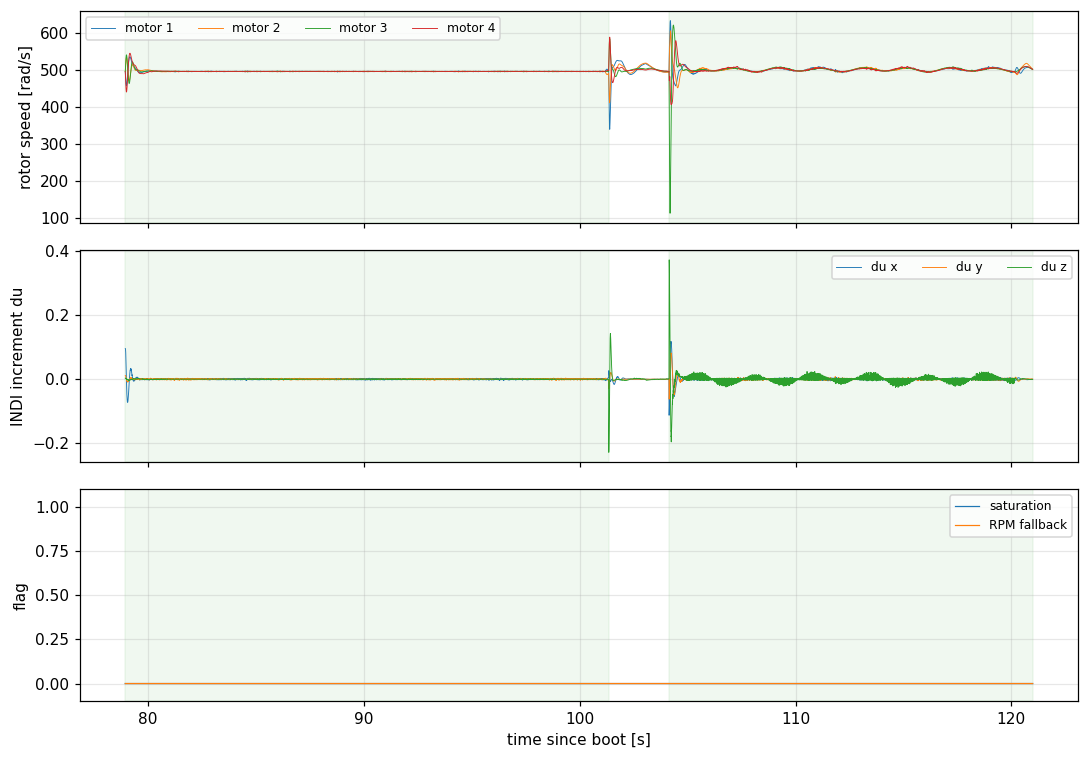

In [10]:
indi = logs["after (X)"]["series"]["INDI"]
indc = logs["after (X)"]["series"]["INDC"]
t_engaged = (indb["t"][blocks[0][0]], indb["t"][blocks[-1][1] - 1])
in_indi = (indi["t"] >= t_engaged[0]) & (indi["t"] <= t_engaged[1])
in_indc = (indc["t"] >= t_engaged[0]) & (indc["t"] <= t_engaged[1])

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for k in range(4):
    axes[0].plot(indc["t"][in_indc], indc[f"O{k}"][in_indc], lw=0.6, label=f"motor {k + 1}")
axes[0].set_ylabel("rotor speed [rad/s]")
axes[0].legend(ncol=4, fontsize=8)
for k, axis in enumerate("xyz"):
    axes[1].plot(indi["t"][in_indi], indi[f"D{axis}"][in_indi], lw=0.6, label=f"du {axis}")
axes[1].set_ylabel("INDI increment du")
axes[1].legend(ncol=3, fontsize=8)
axes[2].plot(indi["t"][in_indi], indi["S"][in_indi], lw=0.8, label="saturation")
axes[2].plot(indc["t"][in_indc], indc["FB"][in_indc], lw=0.8, label="RPM fallback")
axes[2].set_ylim(-0.1, 1.1)
axes[2].set_ylabel("flag")
axes[2].set_xlabel("time since boot [s]")
axes[2].legend(fontsize=8)
for ax in axes:
    for i, j in blocks:
        ax.axvspan(indb["t"][i], indb["t"][j - 1], color="tab:green", alpha=0.07)
fig.tight_layout()

sat_frac = indi["S"][in_indi].mean()
fallback_frac = indc["FB"][in_indc].mean()
print(f"saturation fraction : {sat_frac:.4f}  (gate <= 0.02)")
print(f"RPM fallback frac   : {fallback_frac:.4f}  (gate < 0.5)")
print(f"mean |rotor speed|  : {np.mean([np.abs(indc[f'O{k}'][in_indc]).mean() for k in range(4)]):.1f} rad/s")

## 5. Still open: angular-acceleration inversion fidelity

This gate stays red after the PR, and the PR says so. INDI predicts the body angular
acceleration its increment should produce (`INDI.P*`) and compares it with the filtered
measurement (`INDI.M*`). NRMSE is RMS(pred − meas) / RMS(meas), recomputed here from the
log. The frozen gate is 0.6 on roll and pitch.

The handoff notes that the measurement lags the prediction by about 40–58 ms. Scanning
time shifts shows how much of the NRMSE is phase rather than gain. `exc rms` is RMS(measured ω̇)
in rad/s². NRMSE means little on an axis the trajectory barely excites.

INDI log period 2.50 ms
case            axis    exc rms   NRMSE  scorer  best lag  NRMSE@lag
circle_slow     roll       2.70   1.043   1.043      48 ms      0.255
circle_slow     pitch      0.40   1.456   1.456      40 ms      1.000
lemniscate_fast roll       4.70   1.019   1.019      50 ms      0.193
lemniscate_fast pitch      3.08   1.133   1.133      54 ms      0.265


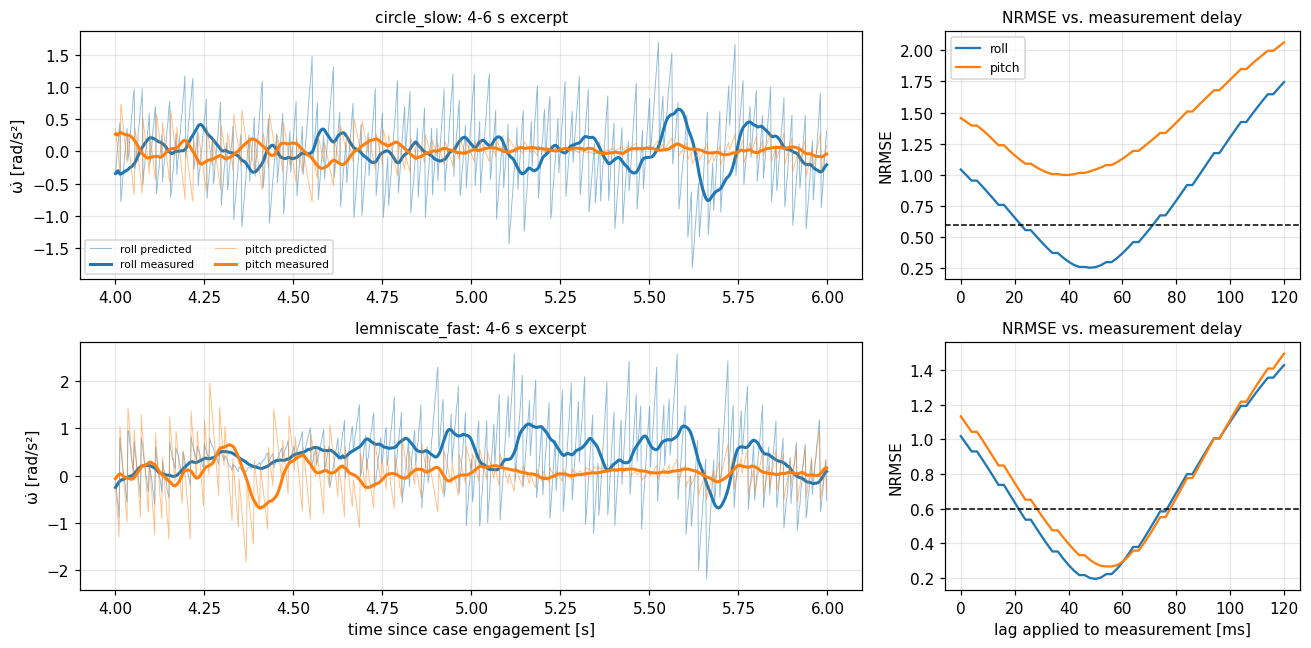

In [11]:
def nrmse(pred, meas):
    return np.sqrt(np.mean((pred - meas) ** 2)) / np.sqrt(np.mean(meas ** 2))


indi_dt = np.median(np.diff(indi["t"]))
lags_ms = np.arange(0, 121, 2)
fig, axes = plt.subplots(len(cases), 2, figsize=(12, 6), gridspec_kw={"width_ratios": [2.2, 1]})
print(f"INDI log period {indi_dt * 1e3:.2f} ms")
print(f"{'case':16s}{'axis':6s}{'exc rms':>9s}{'NRMSE':>8s}{'scorer':>8s}{'best lag':>10s}{'NRMSE@lag':>11s}")
for row, (name, case) in enumerate(cases.items()):
    t_lo, t_hi = indb["t"][case["slice"]][[0, -1]]
    w = (indi["t"] >= t_lo) & (indi["t"] <= t_hi)
    reported_case = next(c for c in score["per_case"] if c["case"] == name)["omega"]
    for axis, label, color in [("x", "roll", "tab:blue"), ("y", "pitch", "tab:orange")]:
        pred, meas = indi[f"P{axis}"][w], indi[f"M{axis}"][w]
        curve = []
        for lag in lags_ms:
            shift = int(round(lag * 1e-3 / indi_dt))
            curve.append(nrmse(pred[: len(pred) - shift], meas[shift:]))
        best = int(np.argmin(curve))
        print(f"{name:16s}{label:6s}{np.sqrt(np.mean(meas ** 2)):9.2f}{nrmse(pred, meas):8.3f}{reported_case[label]['nrmse']:8.3f}"
              f"{lags_ms[best]:8d} ms{curve[best]:11.3f}")
        axes[row, 1].plot(lags_ms, curve, color=color, label=label)
        excerpt = (indi["t"][w] - t_lo > 4) & (indi["t"][w] - t_lo < 6)
        tt = indi["t"][w][excerpt] - t_lo
        axes[row, 0].plot(tt, pred[excerpt], color=color, lw=0.6, alpha=0.5, label=f"{label} predicted")
        axes[row, 0].plot(tt, meas[excerpt], color=color, lw=2.0, label=f"{label} measured")
    axes[row, 0].set_title(f"{name}: 4-6 s excerpt", fontsize=10)
    axes[row, 0].set_ylabel("ω̇ [rad/s²]")
    axes[row, 1].axhline(0.6, color="k", ls="--", lw=1)
    axes[row, 1].set_ylabel("NRMSE")
    axes[row, 1].set_title("NRMSE vs. measurement delay", fontsize=10)
axes[0, 0].legend(ncol=2, fontsize=7)
axes[0, 1].legend(fontsize=8)
axes[-1, 0].set_xlabel("time since case engagement [s]")
axes[-1, 1].set_xlabel("lag applied to measurement [ms]")
fig.tight_layout()

## Summary

The cell below re-evaluates each gate from the log values computed above.

In [12]:
after = logs["after (X)"]["parameters"]
check = handover["after (X)"]["handover"]
track_rms = {n: np.sqrt(np.mean(c["error"] ** 2)) for n, c in cases.items()}
worst_nrmse = max(c["omega"][a]["nrmse"] for c in score["per_case"] for a in ("roll", "pitch"))
rows = [
    ("X layout logged", after["FRAME_CLASS"] == 1 and after["FRAME_TYPE"] == 1,
     f"FRAME_TYPE={after['FRAME_TYPE']:g}"),
    ("stock hold settles before handover", check["peak_roll_pitch_rate_rad_s"] < RATE_LIMIT_RAD_S,
     f"{check['peak_roll_pitch_rate_rad_s']:.4f} rad/s (before fix: aborted, ~4.4 rad/s)"),
    *[(f"tracking {n}", track_rms[n] <= 1.5 * baseline[n],
       f"{track_rms[n]:.3f} m vs gate {1.5 * baseline[n]:.3f} m") for n in cases],
    ("no saturation", sat_frac <= 0.02, f"{sat_frac:.4f}"),
    ("measured-RPM path live", fallback_frac < 0.5, f"fallback {fallback_frac:.4f}"),
    ("ω̇ inversion NRMSE (open, not claimed)", worst_nrmse <= 0.6, f"worst {worst_nrmse:.3f} vs 0.6"),
]
for label, ok, detail in rows:
    print(f"{'PASS' if ok else 'OPEN' if 'open' in label else 'FAIL':5s} {label:42s} {detail}")

PASS  X layout logged                            FRAME_TYPE=1
PASS  stock hold settles before handover         0.0047 rad/s (before fix: aborted, ~4.4 rad/s)
PASS  tracking circle_slow                       0.052 m vs gate 0.727 m
PASS  tracking lemniscate_fast                   0.406 m vs gate 1.067 m
PASS  no saturation                              0.0000
PASS  measured-RPM path live                     fallback 0.0000
OPEN  ω̇ inversion NRMSE (open, not claimed)     worst 1.456 vs 0.6


**Conclusion.** The motor-ordering fix does what PR #646 claims. The stock hold goes from a
sustained 4.4 rad/s limit cycle to a 0.005 rad/s settle. Under INDI, both cases track well
inside the baseline gate, with no saturation and a live measured-RPM path. The two transients
inside the active window come from case sequencing (origin latch and abrupt reference stop),
not from the frame fix. The remaining red gate is the ω̇-inversion NRMSE, which the PR
explicitly leaves open. Section 5 shows it is mostly phase. On every well-excited axis, shifting
the measurement by about 50 ms drops NRMSE from about 1.0–1.1 to 0.19–0.27, well under 0.6.
`circle_slow` pitch is the exception: it is barely excited, so its NRMSE stays noise-dominated
at any lag. The source of that delay in the JSON motor dynamics is the next controlled question.